# 02 · Image Data Collection & Processing

**Owner:** Emma Tiffany Umwari (Member B) · **Plan reference:** Section 2A

This notebook turns the team's facial photos into `features/image_features.csv`, the training data for the **Facial Recognition Model** (Phase 3B). All processing lives in [`src/image_pipeline.py`](../src/image_pipeline.py). The CLI app reuses that code, so a face is processed the same way in training and at login.

1. Data inventory & naming check
2. Sample pictures of every member
3. Face detection & alignment
4. Augmentation
5. Robustness of detection and embeddings to augmentation
6. Feature extraction → `image_features.csv`
7. Do the features separate the members?
8. Unauthorized faces
9. Summary & hand-off to the face model

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault("OPENCV_LOG_LEVEL", "ERROR")  # silence OpenCV backend warnings
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config
from src import image_pipeline as ip

config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Photo grids are large: show them inline as JPEG at screen resolution to keep the
# notebook small. The saved report figures (reports/figures/img_*.png) stay at 150 dpi.
%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams["figure.dpi"] = 72

# Plot styling: validated colour-vision-safe palette; one fixed colour per member
MEMBER_COLORS = dict(zip(config.MEMBERS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
MEMBER_MARKERS = dict(zip(config.MEMBERS, ["o", "s", "^", "D"]))  # second cue, so colour isn't the only one
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "legend.frameon": False,
})

def rgb(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / f"img_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Data inventory & naming check

Each member submitted one photo per expression. Raw phone files were normalised by [`src/ingest_biometrics.py`](../src/ingest_biometrics.py):
- renamed to `<member>_<expression>_<take>.jpg`;
- rotated upright using the photo's orientation flag;
- **stripped of all metadata**, because one set of iPhone photos carried GPS coordinates.

In [2]:
from PIL import Image

inventory = []
for path in ip.list_source_images():  # member folders only (skips augmented/)
    if path.parent == config.UNAUTHORIZED_FACES_DIR:
        continue
    meta = ip.parse_image_name(path)  # raises if a name breaks the convention
    with Image.open(path) as im:
        inventory.append({"file": path.name, **meta, "width": im.width, "height": im.height,
                          "format": im.format, "metadata_tags": len(im.getexif()),
                          "size_kb": round(path.stat().st_size / 1024)})
inventory = pd.DataFrame(inventory)
display(inventory)

coverage = inventory.pivot_table(index="member", columns="expression", values="file", aggfunc="count").reindex(
    index=config.MEMBERS, columns=config.EXPRESSIONS)
display(coverage)
assert (coverage == 1).all().all(), "every member needs neutral, smiling and surprised"
print("✓ 4 members × 3 expressions, consistent naming and JPEG format, no metadata left")

,file,member,expression,take,width,height,format,metadata_tags,size_kb
0,emma_neutral_01.jpg,emma,neutral,1,2316,3088,JPEG,0,1588
1,emma_smiling_01.jpg,emma,smiling,1,2316,3088,JPEG,0,1597
2,emma_surprised_01.jpg,emma,surprised,1,2316,3088,JPEG,0,1810
3,hassan_neutral_01.jpg,hassan,neutral,1,478,1080,JPEG,0,37
4,hassan_smiling_01.jpg,hassan,smiling,1,478,1080,JPEG,0,35
5,hassan_surprised_01.jpg,hassan,surprised,1,478,1080,JPEG,0,37
6,parfait_neutral_01.jpg,parfait,neutral,1,1836,2879,JPEG,0,850
7,parfait_smiling_01.jpg,parfait,smiling,1,1836,3189,JPEG,0,908
8,parfait_surprised_01.jpg,parfait,surprised,1,1836,3153,JPEG,0,786
9,peter_neutral_01.jpg,peter,neutral,1,2316,3088,JPEG,0,1087


expression,neutral,smiling,surprised
member,,,
hassan,1,1,1
emma,1,1,1
parfait,1,1,1
peter,1,1,1


✓ 4 members × 3 expressions, consistent naming and JPEG format, no metadata left


**Notes:** all 12 files follow one naming pattern and one format (JPEG, RGB). Resolutions differ by phone, from 478×1080 to 2316×3088, so `load_image` downscales every photo to a longest side of 1024 px. This gives detection a similar scale for everyone and keeps processing fast.

## 2. Sample pictures of every member

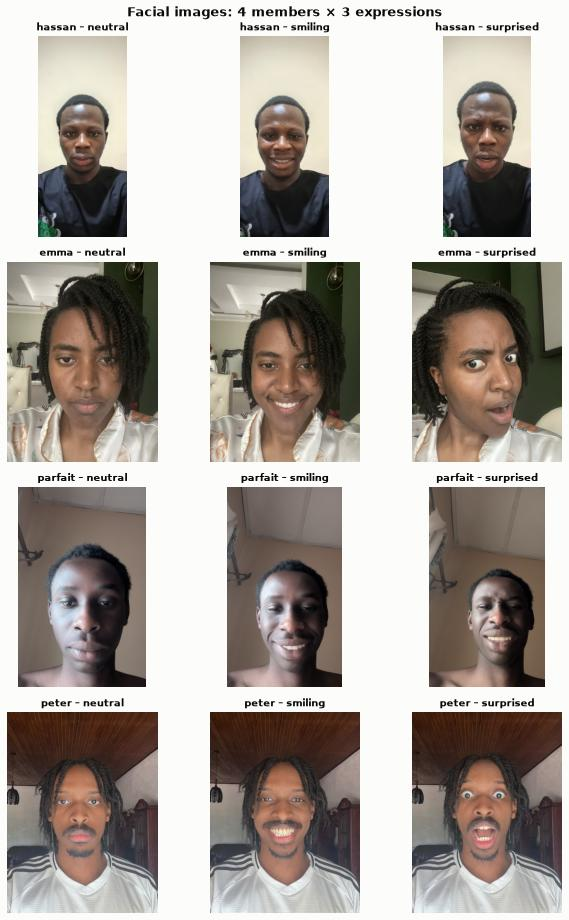

In [3]:
fig, axes = plt.subplots(len(config.MEMBERS), 3, figsize=(9, 13))
for r, member in enumerate(config.MEMBERS):
    for c, expr in enumerate(config.EXPRESSIONS):
        ax = axes[r, c]
        ax.imshow(rgb(ip.load_image(config.IMAGES_DIR / member / f"{member}_{expr}_01.jpg")))
        ax.set_title(f"{member} – {expr}", fontsize=10)
        ax.axis("off")
fig.suptitle("Facial images: 4 members × 3 expressions", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "member_grid")

**Observations:**
- Every member shows three clearly different expressions: relaxed (neutral), teeth showing (smiling), and raised brows with an open mouth (surprised).
- The photos differ in background, from plain wall to living room to ceiling, in lighting, and in framing. Hassan's are tight portrait crops; Peter's and Emma's show more of the room.
- This variety is realistic for login attempts. It also means anything learned from the **whole** photo, such as background colour, could identify the *setting* instead of the *person*. So all features are computed on the detected face only.

## 3. Face detection & alignment

Two pretrained models from the OpenCV Zoo run through `opencv-python`, with no PyTorch or TensorFlow needed:

| Step | Model | Output |
|---|---|---|
| Detect | **YuNet** (2023) | face box, 5 landmarks (eyes, nose, mouth corners), confidence |
| Align | landmark-based similarity transform (`FaceRecognizerSF.alignCrop`) | 112×112 crop with eyes and mouth in fixed positions |
| Embed | **SFace** (2021) | 128-d identity embedding |

Alignment removes head tilt and scale before the embedding is computed. That's why rotated photos still produce similar features (Section 5).

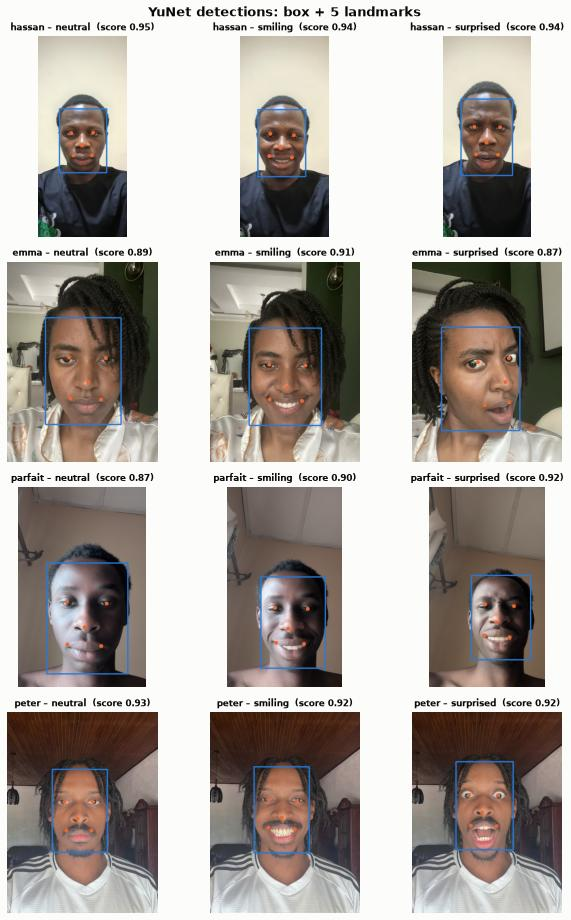

expression,neutral,smiling,surprised
member,,,
hassan,0.947,0.943,0.935
emma,0.891,0.908,0.868
parfait,0.873,0.901,0.920
peter,0.931,0.925,0.924


In [4]:
fig, axes = plt.subplots(len(config.MEMBERS), 3, figsize=(9, 13))
crops, det_rows = {}, []
for r, member in enumerate(config.MEMBERS):
    for c, expr in enumerate(config.EXPRESSIONS):
        img = ip.load_image(config.IMAGES_DIR / member / f"{member}_{expr}_01.jpg")
        face = ip.detect_face(img)
        crops[(member, expr)] = ip.align_face(img, face)
        det_rows.append({"member": member, "expression": expr, "score": round(face.score, 3),
                         "box_w×h": f"{face.box[2]}×{face.box[3]}"})
        vis = rgb(img).copy()
        x, y, w, h = face.box
        thick = max(2, img.shape[0] // 200)
        cv2.rectangle(vis, (x, y), (x + w, y + h), (42, 120, 214), thick)
        for lx, ly in face.landmarks.astype(int):
            cv2.circle(vis, (lx, ly), thick * 2, (235, 104, 52), -1)
        ax = axes[r, c]
        ax.imshow(vis)
        ax.set_title(f"{member} – {expr}  (score {face.score:.2f})", fontsize=9)
        ax.axis("off")
fig.suptitle("YuNet detections: box + 5 landmarks", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "detections")
display(pd.DataFrame(det_rows).pivot(index="member", columns="expression", values="score").reindex(config.MEMBERS))

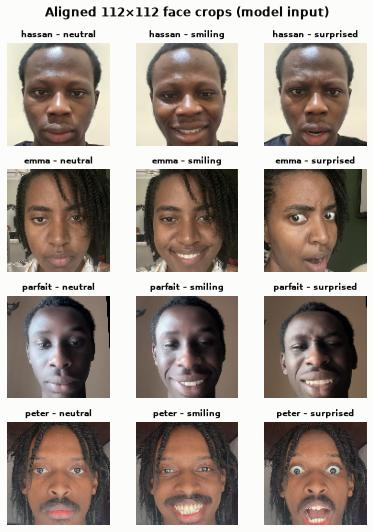

In [5]:
fig, axes = plt.subplots(len(config.MEMBERS), 3, figsize=(5.5, 7.5))
for r, member in enumerate(config.MEMBERS):
    for c, expr in enumerate(config.EXPRESSIONS):
        axes[r, c].imshow(rgb(crops[(member, expr)]))
        axes[r, c].set_title(f"{member} – {expr}", fontsize=8)
        axes[r, c].axis("off")
fig.suptitle("Aligned 112×112 face crops (model input)", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "aligned_crops")

**Result:** the detector finds exactly one face in all 12 photos, with confidence 0.86–0.95 (the acceptance threshold is 0.60). The aligned crops look consistent: eyes level and at the same height, face filling the frame, background mostly gone. The features in Section 6 are computed only on these crops.

## 4. Augmentation

Each photo gets **8 augmentations**, well above the rubric's 2 or more. Each one simulates a condition the login camera could face:

| Augmentation | Parameters | Simulates |
|---|---|---|
| `rotate_p15`, `rotate_m15` | ±15° about the centre, reflected border | tilted head or phone |
| `flip` | horizontal mirror | front-camera mirroring |
| `grayscale` | BGR → grey → 3-channel | colour-less / IR-like camera, white-balance loss |
| `brighter` | contrast ×1.25, +30 | overexposure, bright window |
| `darker` | contrast ×0.6, −10 | dim room |
| `blur` | Gaussian 9×9 | out of focus, motion |
| `noise` | Gaussian σ = 15, fixed seed | low-light sensor noise |

The augmentations are deterministic, using a fixed seed for noise, so rerunning the pipeline reproduces `image_features.csv` exactly. They are applied to the **full photo before detection**, so the detector and aligner have to cope with them, just as they would at login.

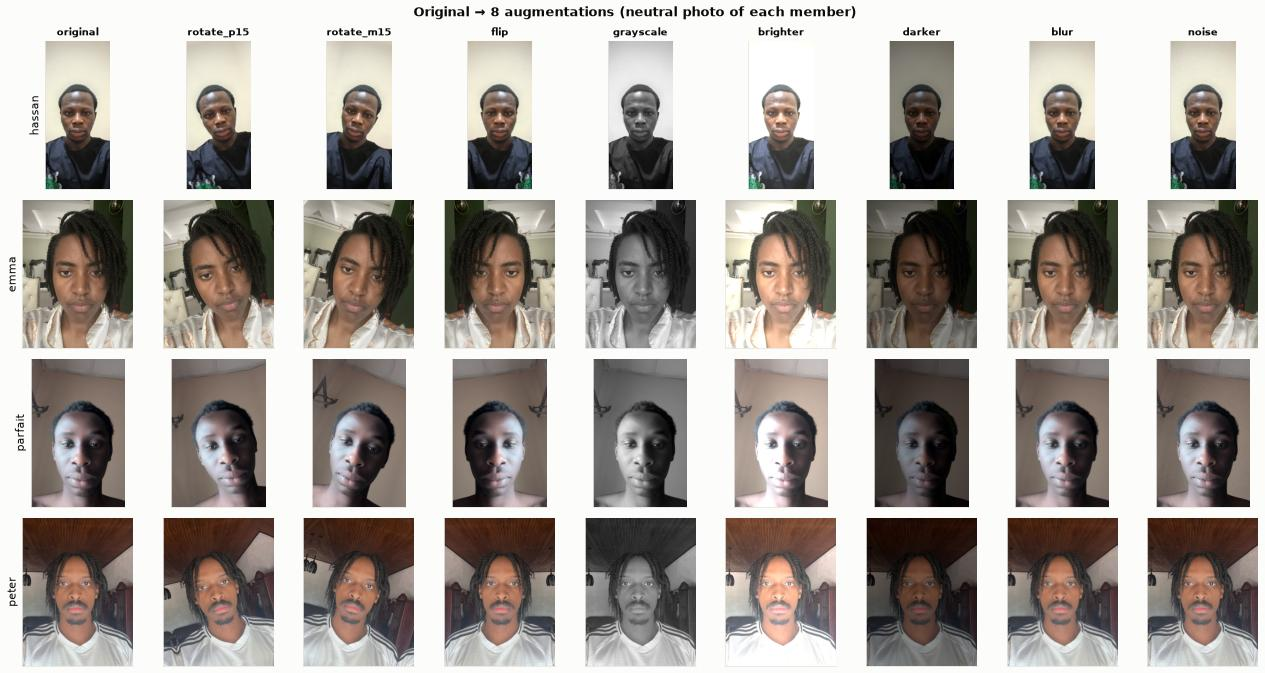

In [6]:
aug_names = ["original"] + list(ip.AUGMENTATIONS)
fig, axes = plt.subplots(len(config.MEMBERS), len(aug_names), figsize=(18, 9.5))
for r, member in enumerate(config.MEMBERS):
    versions = ip.augment(ip.load_image(config.IMAGES_DIR / member / f"{member}_neutral_01.jpg"))
    for c, name in enumerate(aug_names):
        ax = axes[r, c]
        ax.imshow(rgb(versions[name]))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if r == 0:
            ax.set_title(name, fontsize=10)
        if c == 0:
            ax.set_ylabel(member, fontsize=11, color=INK)
fig.suptitle("Original → 8 augmentations (neutral photo of each member)", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "augmentations")

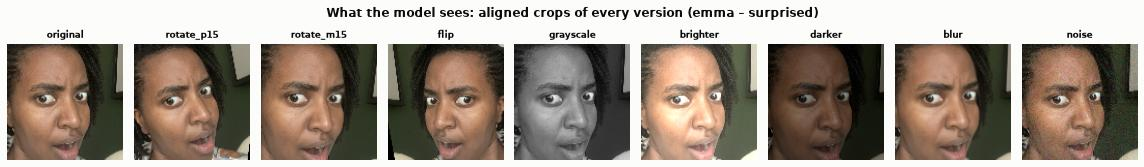

In [7]:
member = "emma"
versions = ip.augment(ip.load_image(config.IMAGES_DIR / member / f"{member}_surprised_01.jpg"))
fig, axes = plt.subplots(1, len(aug_names), figsize=(16, 2.4))
for ax, name in zip(axes, aug_names):
    img = versions[name]
    ax.imshow(rgb(ip.align_face(img, ip.detect_face(img))))
    ax.set_title(name, fontsize=9); ax.axis("off")
fig.suptitle(f"What the model sees: aligned crops of every version ({member} – surprised)", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "augmentations_aligned")

**Observation:** after alignment, the ±15° rotations come out upright again, because the landmarks undo the tilt. The flip mirrors the face, and the photometric changes (grey, bright, dark, blur, noise) are still clearly visible. The rotation augmentations mainly test **detection and alignment**, while the photometric ones test the **embedding**.

## 5. Robustness of detection and embeddings to augmentation

In [8]:
features = ip.build_image_features(save_augmented=True)

Source images : 12 (0 unauthorized)
Rows          : 108 = 12 x (original + 8 augmentations)
Columns       : 194 (8 meta + 128 emb + 48 hist + 10 lbp)
Faces detected: 108/108
Nulls         : 0
Saved to      : features/image_features.csv


,faces_detected,images,mean_det_score,mean_cos_to_original,min_cos_to_original
augmentation,,,,,
original,12,12,0.914,1.000,1.000
rotate_p15,12,12,0.908,0.941,0.828
rotate_m15,12,12,0.904,0.936,0.858
flip,12,12,0.910,0.937,0.910
grayscale,12,12,0.904,0.929,0.884
brighter,12,12,0.904,0.935,0.873
darker,12,12,0.913,0.949,0.879
blur,12,12,0.915,0.969,0.947
noise,12,12,0.897,0.864,0.738


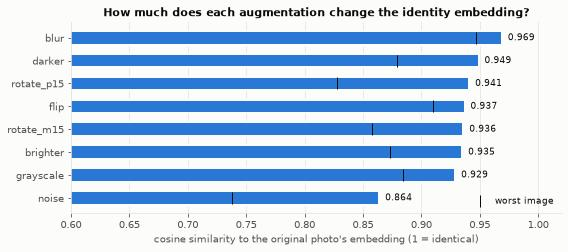

In [9]:
emb = features[ip.EMB_COLS].to_numpy()
orig = features[features["augmentation"] == "original"].set_index("source_image")[ip.EMB_COLS]
features = features.assign(cos_to_original=[
    float(emb[i] @ orig.loc[s].to_numpy()) for i, s in enumerate(features["source_image"])
])

robust = (features.groupby("augmentation")
          .agg(faces_detected=("face_detected", "sum"), images=("face_detected", "size"),
               mean_det_score=("det_score", "mean"), mean_cos_to_original=("cos_to_original", "mean"),
               min_cos_to_original=("cos_to_original", "min"))
          .reindex(aug_names).round(3))
display(robust)

plot = robust.drop(index="original").sort_values("mean_cos_to_original")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(plot.index, plot["mean_cos_to_original"], color="#2a78d6", height=0.6, edgecolor=SURFACE, linewidth=2)
ax.errorbar(plot["min_cos_to_original"], plot.index, fmt="|", color=INK, markersize=12, label="worst image")
for y, v in enumerate(plot["mean_cos_to_original"]):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=8.5, color=INK)
ax.set_xlim(0.6, 1.02)
ax.set_xlabel("cosine similarity to the original photo's embedding (1 = identical)")
ax.set_title("How much does each augmentation change the identity embedding?")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
save(fig, "augmentation_robustness")

**Interpretation**

- **Detection is fully robust:** a face is found in all 108 versions, and the mean confidence stays at 0.90–0.92 for every augmentation. No row needs the "no face" fallback.
- **The embedding barely moves for most augmentations:** blur (0.97), darker (0.95), flip and rotations (about 0.94), brighter (0.94) and grayscale (0.93) all stay very close to the original. SFace was trained to ignore lighting and pose.
- **Noise is the hardest case** (mean 0.86, worst 0.74). Pixel noise disrupts the fine texture the network relies on, and some versions drift noticeably. If the face model struggles, it's likely to be on noisy or low-light inputs. Training on these noisy copies is exactly what should make it more tolerant.

## 6. Feature extraction → `image_features.csv`

In [10]:
saved = pd.read_csv(config.IMAGE_FEATURES_CSV)
n_versions = 1 + len(ip.AUGMENTATIONS)

checks = pd.DataFrame([
    ("rows = source images × (1 + augmentations)", len(saved) == saved["source_image"].nunique() * n_versions,
     f"{len(saved)} = {saved['source_image'].nunique()} × {n_versions}"),
    ("no nulls", saved.isna().sum().sum() == 0, f"{int(saved.isna().sum().sum())}"),
    ("image_id unique", saved["image_id"].is_unique, ""),
    ("face found in every row", saved["face_detected"].all(), f"{saved['face_detected'].sum()}/{len(saved)}"),
    ("embeddings unit-length", np.allclose(np.linalg.norm(saved[ip.EMB_COLS], axis=1), 1), ""),
    ("histograms sum to 1 per channel", np.allclose(saved[ip.HIST_COLS].to_numpy().reshape(len(saved), 3, -1).sum(-1), 1), ""),
], columns=["check", "passed", "detail"])
display(checks)
assert checks["passed"].all()

display(pd.DataFrame({
    "group": ["metadata", "SFace embedding", "colour histogram", "LBP texture histogram"],
    "columns": ["image_id, member, expression, take, augmentation, source_image, face_detected, det_score",
                "emb_0 … emb_127", "hist_0 … hist_47 (16 bins × B, G, R)", "lbp_0 … lbp_9 (uniform LBP, P=8, R=1)"],
    "count": [len(ip.META_COLS), ip.N_EMB, ip.N_HIST, ip.N_LBP],
    "captures": ["labels; source_image is the grouping key for leakage-free splits",
                 "identity (face shape and proportions)", "skin tone + lighting + camera colour",
                 "local skin/hair texture"],
}))
print(f"image_features.csv: {saved.shape[0]} rows × {saved.shape[1]} columns")
saved.iloc[:5, :12]

,check,passed,detail
0,rows = source images × (1 + augmentations),True,108 = 12 × 9
1,no nulls,True,0
2,image_id unique,True,
3,face found in every row,True,108/108
4,embeddings unit-length,True,
5,histograms sum to 1 per channel,True,


,group,columns,count,captures
0,metadata,"image_id, member, expression, take, augmentati...",8,labels; source_image is the grouping key for l...
1,SFace embedding,emb_0 … emb_127,128,identity (face shape and proportions)
2,colour histogram,"hist_0 … hist_47 (16 bins × B, G, R)",48,skin tone + lighting + camera colour
3,LBP texture histogram,"lbp_0 … lbp_9 (uniform LBP, P=8, R=1)",10,local skin/hair texture


image_features.csv: 108 rows × 194 columns


,image_id,member,expression,take,augmentation,source_image,face_detected,det_score,emb_0,emb_1,emb_2,emb_3
0,emma_neutral_01__original,emma,neutral,1,original,emma_neutral_01,1,0.891178,-0.065429,0.032954,-0.049848,-0.108439
1,emma_neutral_01__rotate_p15,emma,neutral,1,rotate_p15,emma_neutral_01,1,0.902569,-0.048621,0.019270,-0.000633,-0.114825
2,emma_neutral_01__rotate_m15,emma,neutral,1,rotate_m15,emma_neutral_01,1,0.848302,-0.100700,-0.002697,0.009421,-0.100841
3,emma_neutral_01__flip,emma,neutral,1,flip,emma_neutral_01,1,0.886605,-0.068930,0.035625,0.010583,-0.090588
4,emma_neutral_01__grayscale,emma,neutral,1,grayscale,emma_neutral_01,1,0.880105,-0.095331,0.005373,0.008740,-0.079423


**Why three feature groups:** the rubric asks for "embeddings / histograms", and each group captures something different.
- The **embedding** is the main identity signal.
- The **colour histogram** and **LBP texture** are cheap, readable descriptors. They are useful as a baseline and for showing what simpler features can and can't do (next section).

`source_image` links every augmented row to its original photo. The face model **must** split train and test on this column, otherwise augmented copies of a test photo leak into training.

## 7. Do the features separate the members?

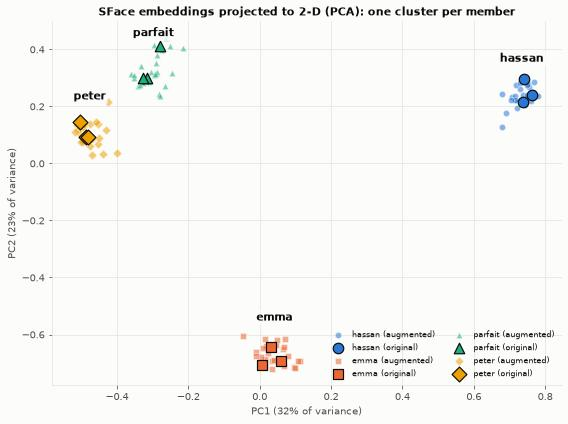

In [11]:
pca = PCA(n_components=2, random_state=config.RANDOM_STATE)
xy = pca.fit_transform(saved[ip.EMB_COLS])

fig, ax = plt.subplots(figsize=(8, 6))
for m in config.MEMBERS:
    sel = (saved["member"] == m).to_numpy()
    is_orig = (saved["augmentation"] == "original").to_numpy()
    ax.scatter(xy[sel & ~is_orig, 0], xy[sel & ~is_orig, 1], s=40, marker=MEMBER_MARKERS[m],
               color=MEMBER_COLORS[m], alpha=0.55, edgecolor=SURFACE, linewidth=0.8, label=f"{m} (augmented)")
    ax.scatter(xy[sel & is_orig, 0], xy[sel & is_orig, 1], s=110, marker=MEMBER_MARKERS[m],
               color=MEMBER_COLORS[m], edgecolor=INK, linewidth=1.2, label=f"{m} (original)")
    cx, cy = xy[sel].mean(axis=0)
    ax.annotate(m, (cx, cy), xytext=(0, 34), textcoords="offset points", ha="center",
                fontsize=11, fontweight="bold", color=INK,
                bbox={"boxstyle": "round,pad=0.2", "fc": SURFACE, "ec": "none", "alpha": 0.85})
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("SFace embeddings projected to 2-D (PCA): one cluster per member")
ax.legend(fontsize=8, ncols=2, loc="best")
fig.tight_layout()
save(fig, "embedding_pca")

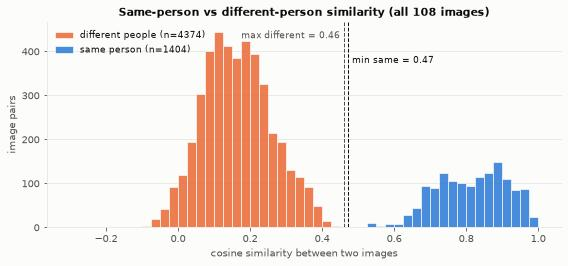

same person: mean 0.814, min 0.473 | different people: mean 0.165, max 0.460 | overlapping pairs: 0


In [12]:
E = saved[ip.EMB_COLS].to_numpy()
S = E @ E.T
iu = np.triu_indices(len(saved), 1)
members = saved["member"].to_numpy()
same = S[iu][members[iu[0]] == members[iu[1]]]
diff = S[iu][members[iu[0]] != members[iu[1]]]

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(-0.3, 1.0, 53)
ax.hist(diff, bins=bins, color="#eb6834", alpha=0.85, label=f"different people (n={len(diff)})", edgecolor=SURFACE, linewidth=0.8)
ax.hist(same, bins=bins, color="#2a78d6", alpha=0.85, label=f"same person (n={len(same)})", edgecolor=SURFACE, linewidth=0.8)
ax.axvline(diff.max(), color=INK_2, ls="--", lw=1)
ax.axvline(same.min(), color=INK, ls="--", lw=1)
ax.text(diff.max() - 0.01, ax.get_ylim()[1] * 0.92, f"max different = {diff.max():.2f}", ha="right", fontsize=8.5, color=INK_2)
ax.text(same.min() + 0.01, ax.get_ylim()[1] * 0.80, f"min same = {same.min():.2f}", ha="left", fontsize=8.5, color=INK)
ax.set_xlabel("cosine similarity between two images")
ax.set_ylabel("image pairs")
ax.set_title("Same-person vs different-person similarity (all 108 images)")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=9, loc="upper left")
fig.tight_layout()
save(fig, "similarity_distribution")
print(f"same person: mean {same.mean():.3f}, min {same.min():.3f} | "
      f"different people: mean {diff.mean():.3f}, max {diff.max():.3f} | overlapping pairs: {(diff >= same.min()).sum()}")

In [13]:
# Sanity check (not the face model): nearest member-centroid, holding out each source photo
# together with ALL its augmentations, so no copy of the test photo is seen in "training".
def loso_nearest_centroid(cols, cosine):
    correct = 0
    for src in saved["source_image"].unique():
        train, test = saved[saved["source_image"] != src], saved[saved["source_image"] == src]
        cents = train.groupby("member")[cols].mean()
        X, C = test[cols].to_numpy(), cents.to_numpy()
        if cosine:
            C = C / np.linalg.norm(C, axis=1, keepdims=True)
            pred = cents.index[np.argmax(X @ C.T, axis=1)]
        else:
            pred = cents.index[np.argmin(((X[:, None] - C[None]) ** 2).sum(-1), axis=1)]
        correct += (pred == test["member"].to_numpy()).sum()
    return correct / len(saved)

pd.DataFrame({
    "feature group": ["SFace embedding (128)", "colour histogram (48)", "LBP texture (10)"],
    "held-out-photo accuracy": [loso_nearest_centroid(ip.EMB_COLS, True),
                                loso_nearest_centroid(ip.HIST_COLS, False),
                                loso_nearest_centroid(ip.LBP_COLS, False)],
}).round(3)

,feature group,held-out-photo accuracy
0,SFace embedding (128),1.000
1,colour histogram (48),0.713
2,LBP texture (10),0.778


**Interpretation**

- **Clear clusters:** in the PCA plot each member forms a separate cluster. The augmented versions (small markers) stay close to their originals (large markers with outlines). Two components keep only about 56% of the variance, so the full 128-d separation is stronger than the plot suggests.
- **No overlap in similarity:** two images of the same person always score higher than any pair of different people. Typical values are about 0.81 for the same person vs 0.17 for different people. The extremes are close, though:
  - the weakest same-person pair (0.47) is Parfait's *noisy* surprised photo vs his rotated smiling one, and all of the weakest pairs involve that noisy copy;
  - the most similar different-person pair (0.46) is Peter vs Parfait, the two clusters closest together in the PCA plot.

  This similarity gap is the basis for the "unknown face" threshold in Phase 3B. Peter/Parfait confusion and noisy inputs are the cases to watch.
- **The embedding generalises to unseen photos:** holding out each photo together with all its augmentations, a simple nearest-centroid rule identifies the member **100%** of the time from embeddings.
- **The simpler features are weaker and confounded:** LBP texture scores about 78% and colour histograms about 71%. Each member took all their photos in one room under one light, so colour partly encodes *where the photo was taken*. A new photo in different lighting could fool a histogram-only model. **The face model should rely on the embedding**, with histogram and LBP features at most as secondary inputs.

## 8. Unauthorized faces

In [14]:
n_unknown = (saved["member"] == config.UNKNOWN_LABEL).sum()
files = [p.name for p in config.UNAUTHORIZED_FACES_DIR.glob("*") if p.name != ".gitkeep"]
print(f"Files in {config.UNAUTHORIZED_FACES_DIR.relative_to(config.ROOT)}: {files or 'none yet'}")
print(f"Rows labelled '{config.UNKNOWN_LABEL}' in image_features.csv: {n_unknown}")

Files in data/unauthorized/faces: none yet
Rows labelled 'unknown' in image_features.csv: 0


Non-member faces are collected by **Member D** (Plan 1A). `build_image_features` already includes any `.jpg`/`.png` in `data/unauthorized/faces/` and labels them `unknown`, with the same 8 augmentations. **Once D adds the files, rerun `python src/image_pipeline.py`**; no code changes are needed. Until then, the face model can still reject strangers by thresholding similarity (Section 7). The `unknown` rows will then let the threshold be tuned and tested on real impostors.

## 9. Summary & hand-off to the face model (Phase 3B)

| Item | Result |
|---|---|
| Images | 4 members × 3 expressions (neutral / smiling / surprised), consistent naming, JPEG, metadata stripped |
| Detection | YuNet found the face in **108/108** images (12 originals + 96 augmented) |
| Augmentations | **8 per image**: ±15° rotation, flip, grayscale, brighter, darker, blur, noise |
| Features | `image_features.csv`: **108 rows × 194 columns** = 8 metadata + 128 embedding + 48 colour histogram + 10 LBP, 0 nulls |
| Separability | same-person similarity always > different-person; held-out-photo nearest-centroid accuracy 100% (embedding) vs about 78% (LBP) and 71% (histogram) |

**Recommendations for 3B:**
1. Split train/test with **`GroupShuffleSplit` / `StratifiedGroupKFold` on `source_image`**, never row-wise.
2. Use the **embedding** as the main input. If histogram/LBP are added, standardise them and check they don't reduce held-out accuracy, given the lighting confound above.
3. Reject unknown faces with a **confidence threshold** on `predict_proba`, optionally combined with cosine similarity to the predicted member's centroid. Tune it once unauthorized samples exist.
4. At login, use exactly `ip.load_image` → `ip.extract_features` → `ip.feature_vector`. If `face_detected == 0`, deny access immediately.